# VitaStress — Feature nuove dai segnali grezzi
Stessa tabella del notebook 03 (21 persone, una riga ogni 30 secondi, 4 fasi, 3 classi). Qui si aggiungono **feature calcolate dai segnali grezzi**, un gruppo alla volta, e si guarda se aiutano a rispondere alla domanda della tesi: **senza il movimento, il braccialetto distingue lo stress mentale dallo sforzo fisico?**

Ogni prova si fa **con e senza movimento**, sempre con Random Forest e leave-one-subject-out come nel notebook 03.

Parte 1: tabella di partenza. Parte 2: magnitudine del movimento. Parte 3: temperatura della pelle. Parte 4: sudore. Parte 5: battito (PPG). Parte 6: tabella completa. Parte 7: prove. Parte 8: MLP con le feature nuove.

# Parte 1 — Tabella di partenza

## Fase 0 — Setup
Come nel notebook 03.

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

if not os.path.exists("VitaStress"):
    !git clone https://github.com/paulvincenz/VitaStress.git

DATA = "VitaStress/data"
persone = sorted([c.replace("id_", "") for c in os.listdir(DATA) if c.startswith("id_")])
ASSI_GIRATI = {"ddca342b": ["accY", "accZ"]}
print("Persone:", len(persone))

BLU, ARANCIO, GRIGIO, VERDE = "#2a78d6", "#eb6834", "#898781", "#1baf7a"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#c3c2b7", "axes.grid": True, "axes.axisbelow": True,
                     "grid.color": "#e1e0d9", "grid.linewidth": 0.8})

Persone: 21


## Fase 1 — Orari, segnali e fasi
Le funzioni del notebook 03 (Fasi 1–3), uguali: orari delle 4 fasi, le 12 feature degli autori ogni 30 secondi, la classe.

In [2]:
fasi = {"baseline": "baseline", "cognitive": "cognitive",
        "public": "public speaking", "physical": "physical"}
classi = {"baseline": 0, "cognitive": 1, "public": 1, "physical": 2}
nomi_classi = ["riposo", "cognitivo", "fisico"]

def trova_orari(persona):
    cartella = DATA + "/id_" + persona + "/" + persona + "_"
    ann = pd.read_csv(cartella + "annotation.csv")
    ann["timestamp"] = pd.to_datetime(ann["timestamp"], format="mixed")
    ann["evento"] = ann["Button Name"].astype(str).str.lower().str.replace(":", "").str.strip(" []'")
    orari = {}
    for fase in fasi:
        nome = fasi[fase]
        inizi = ann[ann["evento"].str.startswith(nome + " start")]["timestamp"]
        fini = ann[ann["evento"].str.startswith(nome + " stop")]["timestamp"].dropna()
        inizi = inizi[inizi < fini.max()]
        if len(inizi) == 0:
            print(persona[:8], fase, "-> manca inizio o fine, salto")
            continue
        inizio = inizi.max()
        fine = fini[fini > inizio].min()
        durata = (fine - inizio).total_seconds() / 60
        if fase == "baseline" and durata > 12:
            print(persona[:8], "-> riposo di", round(durata), "min, tengo gli ultimi 10")
            inizio = fine - pd.Timedelta("10min")
            durata = 10
        if durata > 30:
            print(persona[:8], fase, "-> durata strana:", round(durata, 1), "min, salto")
            continue
        orari[fase] = (inizio, fine)
    return orari

def leggi(cartella, file, colonne):
    dati = pd.read_csv(cartella + file + ".csv", usecols=["date"] + colonne)
    dati["date"] = pd.to_datetime(dati["date"], format="mixed")
    return dati.set_index("date")

def segnali_30s(persona):
    cartella = DATA + "/id_" + persona + "/" + persona + "_"
    bpm = leggi(cartella, "activity", ["bpm"])["bpm"].replace(0, np.nan)
    temp = leggi(cartella, "temperature", ["temp_sk1"])["temp_sk1"].replace(0, np.nan)
    sudore = leggi(cartella, "emography", ["stress_skin"])["stress_skin"]
    tab = pd.DataFrame({
        "bpm": bpm.resample("30s").mean(),
        "temp_sk1": temp.resample("30s").mean(),
        "stress_skin": sudore.resample("30s").mean().ffill(limit=1),
    })
    acc = leggi(cartella, "acc", ["accX", "accY", "accZ"])
    for asse in ["accX", "accY", "accZ"]:
        blocchi = acc[asse].resample("30s")
        tab[asse + "_mean"] = blocchi.mean()
        tab[asse + "_std"] = blocchi.std()
        tab[asse + "_var"] = blocchi.var()
    for asse in ASSI_GIRATI.get(persona[:8], []):
        tab[asse + "_mean"] = -tab[asse + "_mean"]
    return tab, cartella

def dentro_le_fasi(tab, orari):
    pezzi = []
    for fase in orari:
        inizio, fine = orari[fase]
        pezzo = tab[(tab.index >= inizio) & (tab.index < fine)].copy()
        pezzo["fase"] = fase
        pezzi.append(pezzo)
    return pd.concat(pezzi)

# Parte 2 — Magnitudine del movimento

## Fase 2 — Perché la magnitudine
L'accelerometro dà 3 numeri (X, Y, Z). Anche da fermo misura la gravità (circa 512 nelle sue unità), e come si divide fra i tre assi dipende da **come è girato il polso**. Le 9 feature degli autori usano gli assi separati: mescolano la **postura** (come tieni il polso) e l'**agitazione** (quanto ti muovi), e dipendono da come è indossato il braccialetto (vedi `ddca342b`).

La **magnitudine** √(X² + Y² + Z²) è la lunghezza della freccia: da fermo vale sempre circa 512, comunque sia girato il polso, e oscilla quando ti muovi. Misura **solo quanto ti muovi**. Per ogni blocco da 30 s: media e deviazione standard.

Qui si controlla che non dipenda dall'orientamento: a riposo `ddca342b` (braccialetto girato) deve avere la stessa magnitudine degli altri, senza correzioni.

In [3]:
def magnitudine(cartella):
    acc = leggi(cartella, "acc", ["accX", "accY", "accZ"])
    lunghezza = np.sqrt(acc["accX"]**2 + acc["accY"]**2 + acc["accZ"]**2)
    blocchi = lunghezza.resample("30s")
    return pd.DataFrame({"mag_media": blocchi.mean(), "mag_std": blocchi.std()})

riposo = []
for p in persone:
    cartella = DATA + "/id_" + p + "/" + p + "_"
    inizio, fine = trova_orari(p)["baseline"]
    acc = leggi(cartella, "acc", ["accX", "accY", "accZ"])
    acc = acc[(acc.index >= inizio) & (acc.index < fine)]
    riposo.append({"persona": p[:8], "accX": acc["accX"].mean(), "accZ": acc["accZ"].mean(),
                   "magnitudine": np.sqrt(acc["accX"]**2 + acc["accY"]**2 + acc["accZ"]**2).mean()})
riposo = pd.DataFrame(riposo).set_index("persona").round(0)
print(riposo.loc[["ddca342b"]])
print("\nAltre 20 persone (min - max):")
print(riposo.drop("ddca342b").agg(["min", "max"]))

7bb4dafd cognitive -> manca inizio o fine, salto


a5e823ad -> riposo di 82 min, tengo gli ultimi 10


           accX   accZ  magnitudine
persona                            
ddca342b  446.0 -107.0        505.0

Altre 20 persone (min - max):
      accX   accZ  magnitudine
min -508.0   67.0        505.0
max  205.0  492.0        527.0


## Fase 3 — Magnitudine per fase
La prima persona dell'elenco (`0a73ef1b`): la deviazione standard della magnitudine durante l'esperimento. Dovrebbe essere bassa a riposo, nel calcolo e nel discorso, e alta nella corsa.

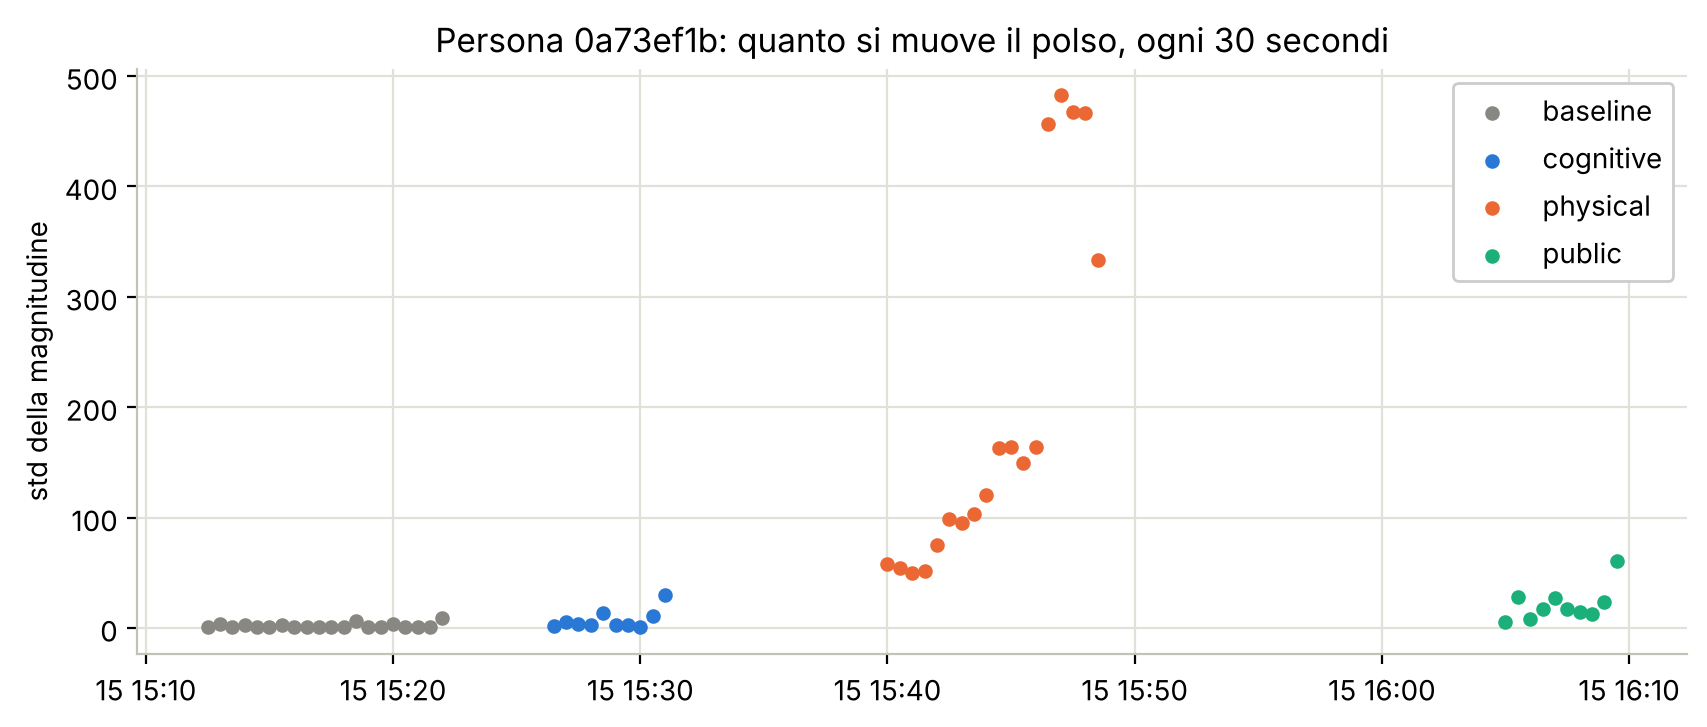

In [4]:
p = persone[0]
tab, cartella = segnali_30s(p)
tab = dentro_le_fasi(tab.join(magnitudine(cartella)), trova_orari(p))
colore_fase = {"baseline": GRIGIO, "cognitive": BLU, "public": VERDE, "physical": ARANCIO}

plt.figure(figsize=(10, 3.8))
for fase, pezzo in tab.groupby("fase"):
    plt.scatter(pezzo.index, pezzo["mag_std"], color=colore_fase[fase], s=18, label=fase)
plt.ylabel("std della magnitudine")
plt.title(f"Persona {p[:8]}: quanto si muove il polso, ogni 30 secondi")
plt.legend(framealpha=1)
plt.show()

# Parte 3 — Temperatura della pelle

## Fase 4 — Cosa misura davvero `temp_sk1`
Nel notebook 03 la temperatura non serviva quasi a niente (permutation importance 0,005). Il file `heat_flux_sensor_temperature` (un valore al secondo) contiene `skin_temp` (pelle), `heatflux` (flusso di calore) e `cbt` (temperatura corporea interna **stimata**). Qui si confronta `temp_sk1`, usata dagli autori, con `cbt` e `skin_temp`, fase per fase.

In [5]:
confronto = []
for p in persone:
    cartella = DATA + "/id_" + p + "/" + p + "_"
    calore = leggi(cartella, "heat_flux_sensor_temperature", ["skin_temp", "heatflux", "cbt"])
    temp = leggi(cartella, "temperature", ["temp_sk1"])["temp_sk1"].replace(0, np.nan)
    for fase, (inizio, fine) in trova_orari(p).items():
        dentro = calore[(calore.index >= inizio) & (calore.index < fine)]
        confronto.append({"fase": fase,
                          "temp_sk1": temp[(temp.index >= inizio) & (temp.index < fine)].mean(),
                          "cbt": dentro["cbt"].mean(),
                          "skin_temp": dentro["skin_temp"].mean(),
                          "heatflux": dentro["heatflux"].mean()})
confronto = pd.DataFrame(confronto)
print("Differenza media fra temp_sk1 e cbt:", round((confronto["temp_sk1"] - confronto["cbt"]).abs().mean(), 3), "°C")
confronto.groupby("fase")[["temp_sk1", "cbt", "skin_temp", "heatflux"]].mean().round(2)

7bb4dafd cognitive -> manca inizio o fine, salto


a5e823ad -> riposo di 82 min, tengo gli ultimi 10
Differenza media fra temp_sk1 e cbt: 0.001 °C


,temp_sk1,cbt,skin_temp,heatflux
fase,,,,
baseline,37.23,37.23,30.09,89.22
cognitive,37.23,37.23,31.12,66.22
physical,37.22,37.22,30.43,84.52
public,37.28,37.28,30.93,77.52


## Fase 5 — Feature della temperatura
Per ogni blocco da 30 s, dalla temperatura della pelle: **media**, **deviazione standard** e **pendenza** (di quanti gradi al minuto sale o scende, con una retta sui 30 valori del blocco). Dal flusso di calore: la **media**. Valori della pelle sotto 15 °C sono errori del sensore e diventano mancanti.

In [6]:
def pendenza(valori):
    valori = valori.dropna()
    if len(valori) < 10:
        return np.nan
    secondi = (valori.index - valori.index[0]).total_seconds()
    return np.polyfit(secondi, valori.values, 1)[0] * 60

def temperatura(cartella):
    calore = leggi(cartella, "heat_flux_sensor_temperature", ["skin_temp", "heatflux"])
    pelle = calore["skin_temp"].where(calore["skin_temp"] > 15)
    return pd.DataFrame({"pelle_media": pelle.resample("30s").mean(),
                         "pelle_std": pelle.resample("30s").std(),
                         "pelle_pendenza": pelle.resample("30s").apply(pendenza),
                         "flusso_media": calore["heatflux"].resample("30s").mean()})

## Fase 6 — La pendenza per fase
La pendenza della pelle ogni 30 secondi per `f9513e4b`, scelta perché per lei il calcolo è l'**ultima** fase. Attenzione: il riposo è **sempre la prima fase**, quando il braccialetto è stato appena messo e si sta ancora scaldando, quindi una pendenza positiva a riposo potrebbe venire solo da questo. Se la pelle si scalda anche nel calcolo alla fine dell'esperimento, la pendenza dice qualcosa sulla fase e non solo sul tempo. Nella Parte 5 si controlla anche il confronto senza il riposo.

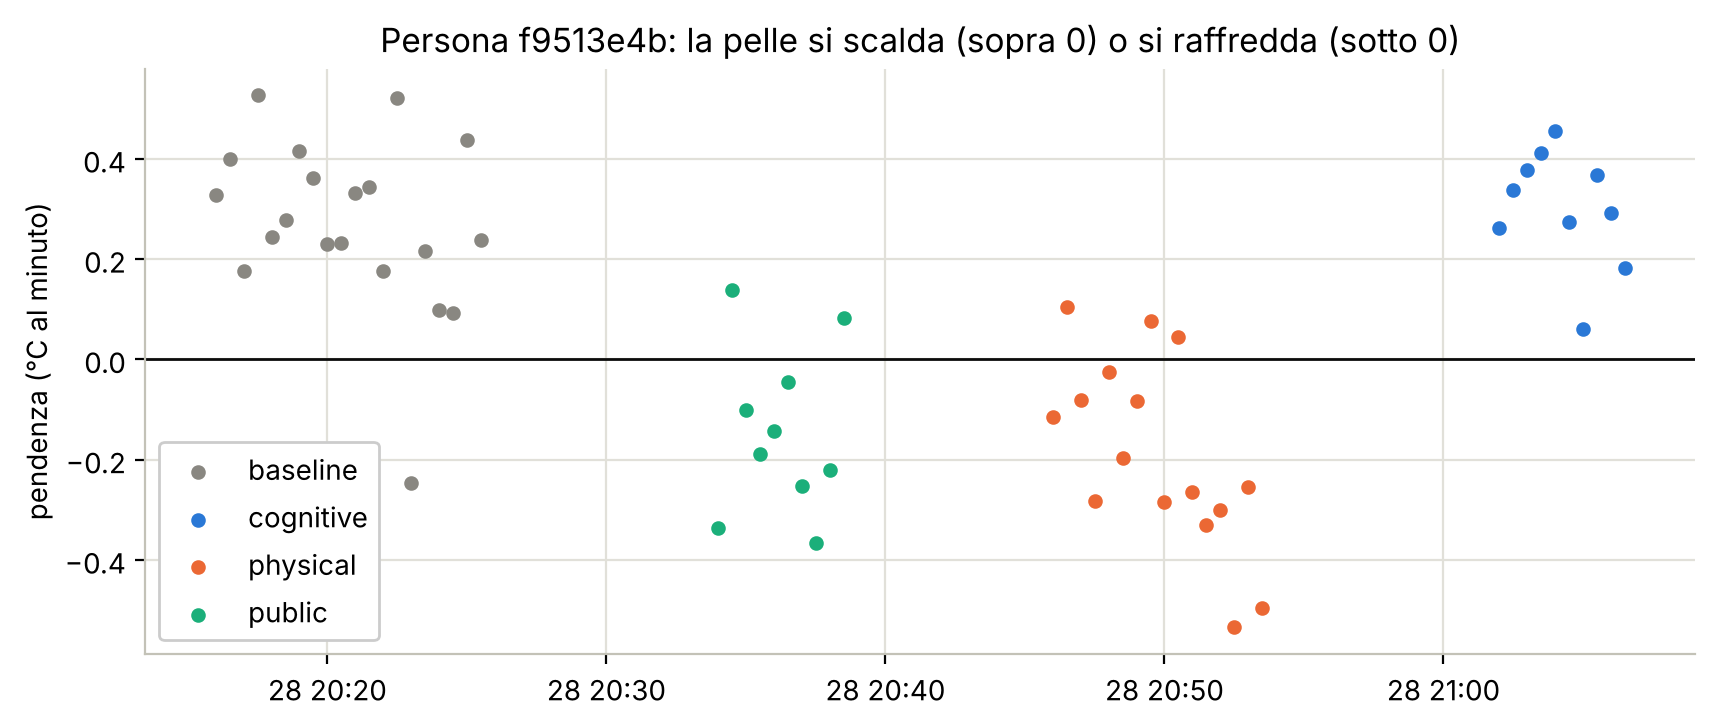

In [7]:
p = [q for q in persone if q.startswith("f9513e4b")][0]
tab, cartella = segnali_30s(p)
tab = dentro_le_fasi(tab.join(temperatura(cartella)), trova_orari(p))

plt.figure(figsize=(10, 3.8))
for fase, pezzo in tab.groupby("fase"):
    plt.scatter(pezzo.index, pezzo["pelle_pendenza"], color=colore_fase[fase], s=18, label=fase)
plt.axhline(0, color="#0b0b0b", linewidth=1)
plt.ylabel("pendenza (°C al minuto)")
plt.title(f"Persona {p[:8]}: la pelle si scalda (sopra 0) o si raffredda (sotto 0)")
plt.legend(framealpha=1)
plt.show()

# Parte 4 — Sudore

## Fase 7 — Il segnale grezzo del sudore
Gli autori usano `stress_skin`, un indice calcolato dal braccialetto una volta al minuto e pieno di zeri. Il file `bioz` contiene il segnale grezzo: la **conduttanza della pelle**, 25 valori al secondo. Quando si suda la pelle conduce di più e il valore sale. Qui si guarda il segnale di due persone, con le fasi colorate.

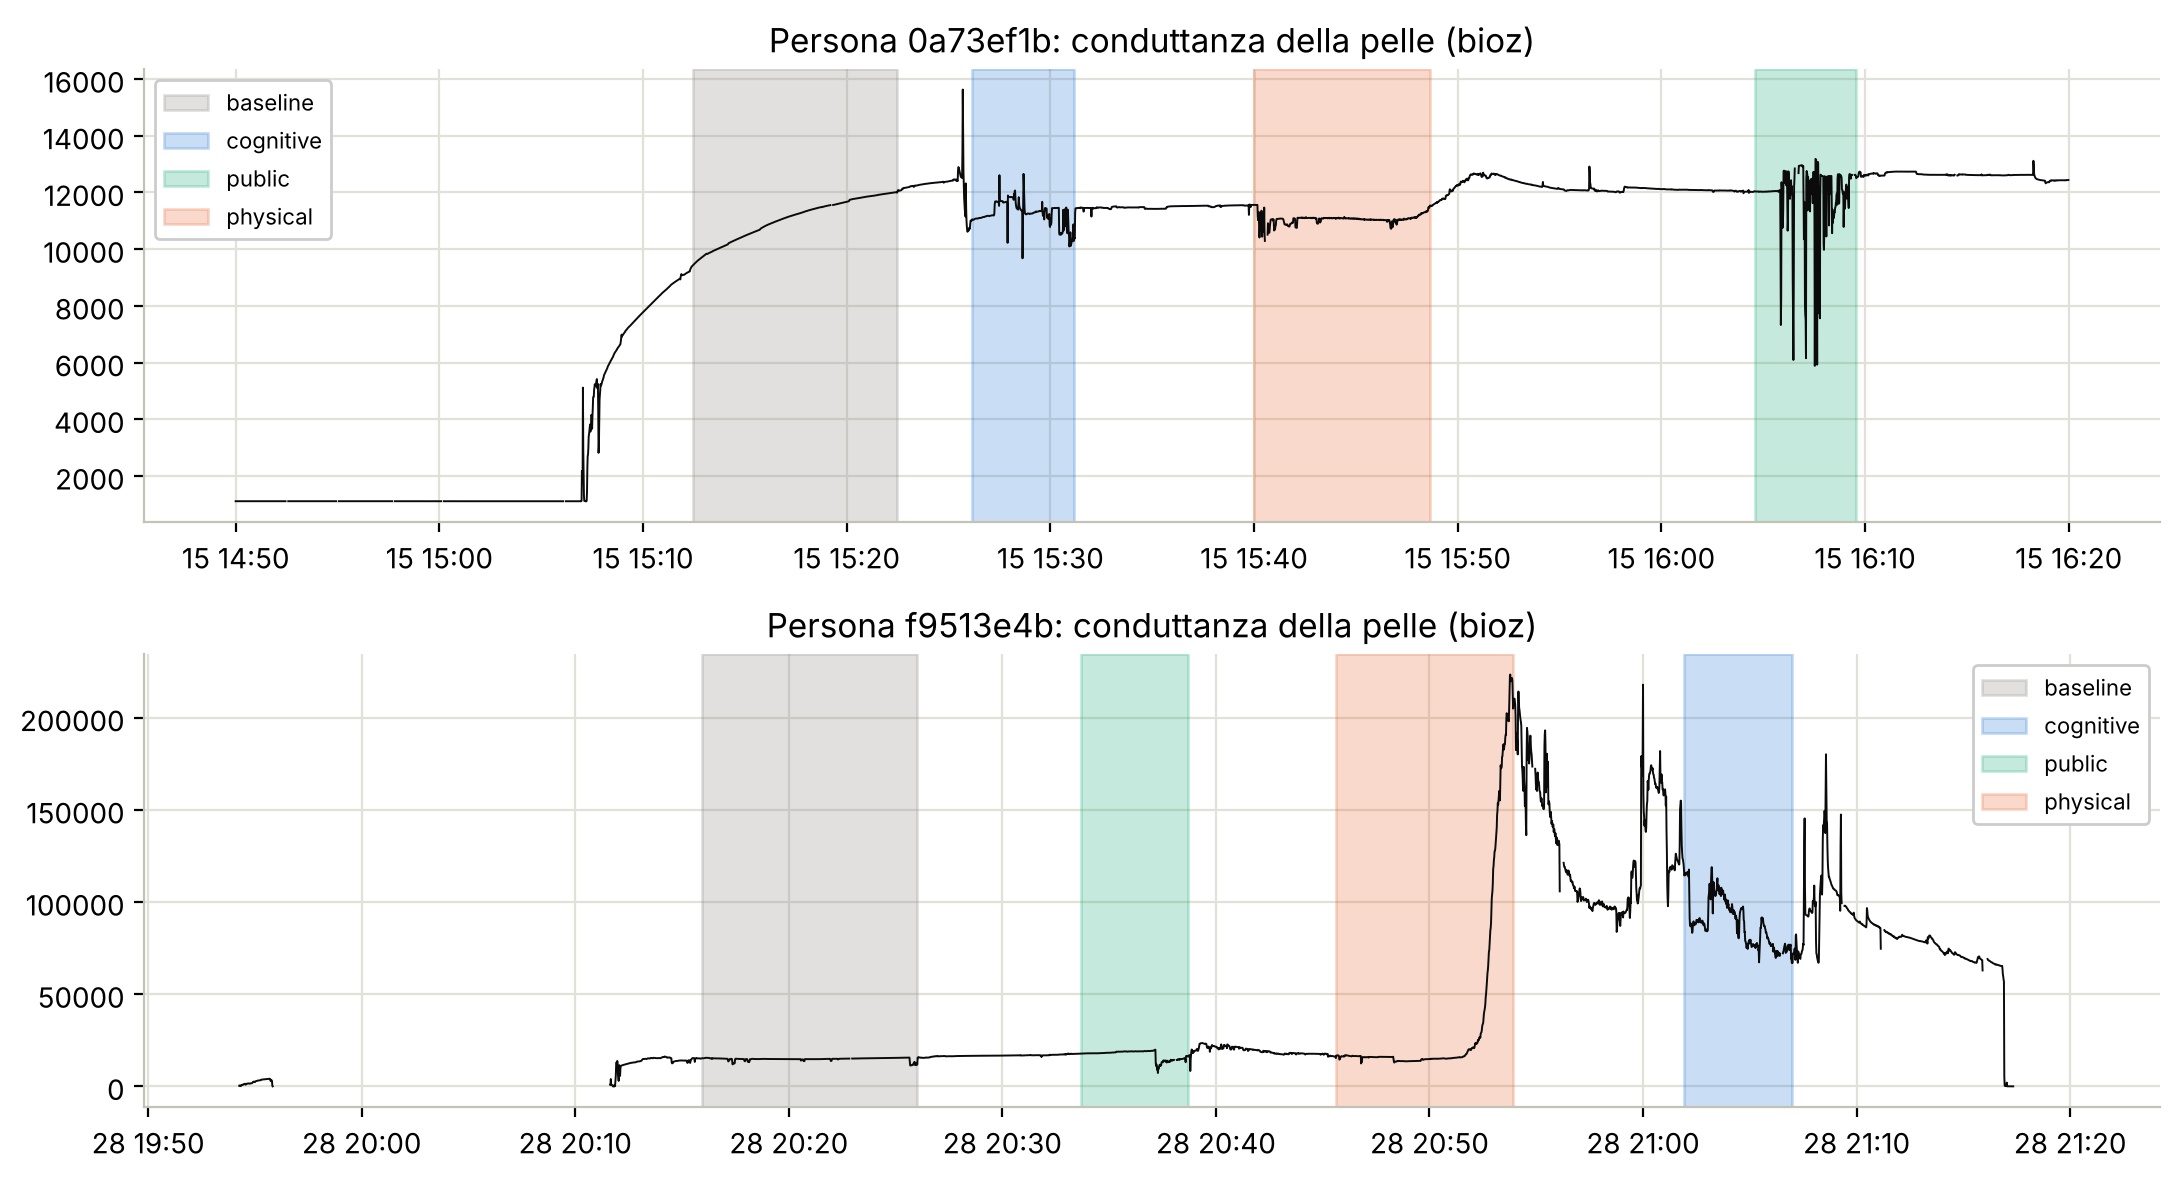

In [8]:
def leggi_sudore(cartella):
    sudore = leggi(cartella, "bioz", ["value"])["value"]
    return sudore.where(sudore > 0)

fig, assi = plt.subplots(2, 1, figsize=(11, 6))
for asse, codice in zip(assi, ["0a73ef1b", "f9513e4b"]):
    p = [q for q in persone if q.startswith(codice)][0]
    cartella = DATA + "/id_" + p + "/" + p + "_"
    sudore = leggi_sudore(cartella).resample("1s").mean()
    asse.plot(sudore.index, sudore.values, color="#0b0b0b", linewidth=0.7)
    for fase, (inizio, fine) in trova_orari(p).items():
        asse.axvspan(inizio, fine, color=colore_fase[fase], alpha=0.25, label=fase)
    asse.set_title(f"Persona {codice}: conduttanza della pelle (bioz)")
    asse.legend(fontsize=8, framealpha=1)
plt.tight_layout()
plt.show()

## Fase 8 — Feature del sudore
Nei grafici si vedono tre cose: a riposo il segnale sta ancora salendo (l'elettrodo si assesta sulla pelle appena messo il braccialetto); dopo la corsa il sudore resta alto per molti minuti; nel discorso ci sono buchi improvvisi, dovuti ai movimenti del polso mentre si gesticola. Il segnale di conduttanza ha due parti. Il **livello** (componente lenta) sale e scende nel giro di minuti; le **reazioni** (componente veloce) sono picchi di pochi secondi, tipici di una risposta a qualcosa che ci attiva.

Per ogni blocco da 30 s: il **livello** (mediana mobile su 20 s), la **pendenza** del segnale e, per le reazioni, **quante** sono e la loro **ampiezza** totale. Il segnale si usa in logaritmo, così un picco del 1% conta uguale per chi ha la pelle più o meno conduttiva; una reazione è un picco che si alza di almeno l'1% (prominenza 0,01) rispetto a ciò che lo circonda.

In [9]:
from scipy.signal import find_peaks

def sudore_feature(cartella):
    segnale = np.log(leggi_sudore(cartella)).resample("250ms").mean().interpolate(limit=8)
    segnale = segnale.rolling(4, center=True, min_periods=1).mean()
    livello = segnale.rolling(80, center=True, min_periods=20).median()
    posizioni, info = find_peaks(segnale.fillna(segnale.median()).values, prominence=0.01, distance=4)
    reazioni = pd.Series(info["prominences"], index=segnale.index[posizioni])
    blocchi = segnale.resample("30s").mean().index
    return pd.DataFrame({"sud_livello": livello.resample("30s").mean(),
                         "sud_pendenza": segnale.resample("30s").apply(pendenza),
                         "sud_reazioni": reazioni.resample("30s").count().reindex(blocchi, fill_value=0),
                         "sud_ampiezza": reazioni.resample("30s").sum().reindex(blocchi, fill_value=0)})

## Fase 9 — Reazioni per fase
Quante reazioni ci sono, in media, in un blocco da 30 secondi di ogni fase. Ci aspettiamo poche reazioni a riposo e di più nei momenti di stress.

In [10]:
conteggi = []
for p in persone:
    cartella = DATA + "/id_" + p + "/" + p + "_"
    feature = sudore_feature(cartella)
    for fase, (inizio, fine) in trova_orari(p).items():
        dentro = feature[(feature.index >= inizio) & (feature.index < fine)]
        conteggi.append({"fase": fase, "reazioni per 30 s": dentro["sud_reazioni"].mean()})
conteggi = pd.DataFrame(conteggi).groupby("fase").mean().round(2)
conteggi

7bb4dafd cognitive -> manca inizio o fine, salto


a5e823ad -> riposo di 82 min, tengo gli ultimi 10


,reazioni per 30 s
fase,
baseline,0.78
cognitive,1.78
physical,1.51
public,2.20


# Parte 5 — Battito (PPG)

## Fase 10 — Il segnale del battito
La **variabilità del battito** (quanto cambia il tempo fra un battito e l'altro) è una delle misure più legate allo stress mentale. Per calcolarla bisogna trovare ogni singolo battito nel segnale del PPG: la luce verde del braccialetto, 62,5 valori al secondo, che pulsa a ogni battito perché il sangue assorbe più luce. Qui si guardano 15 secondi a metà del riposo e a metà del calcolo della stessa persona.

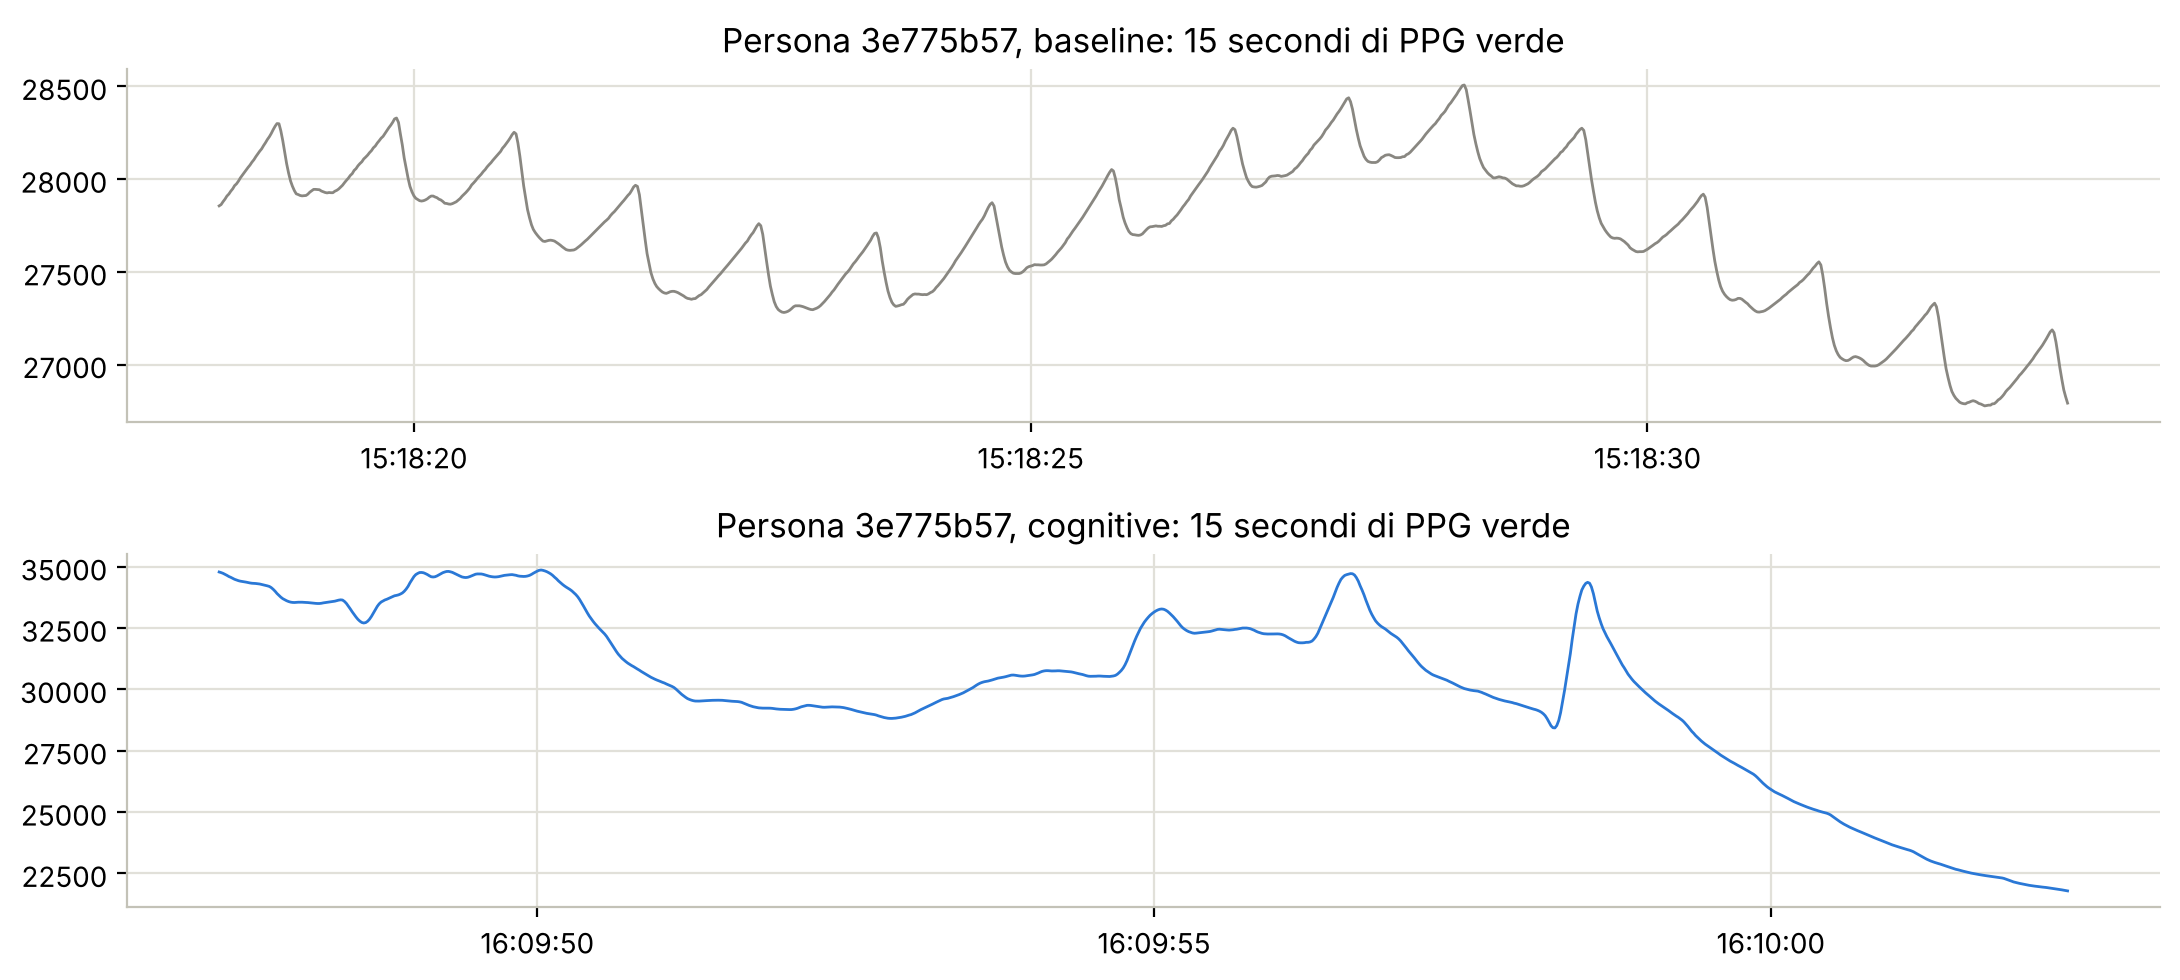

In [11]:
p = [q for q in persone if q.startswith("3e775b57")][0]
cartella = DATA + "/id_" + p + "/" + p + "_"
verde = leggi(cartella, "ppg2_green_6", ["value"])["value"]
orari = trova_orari(p)

fig, assi = plt.subplots(2, 1, figsize=(11, 5))
for asse, fase in zip(assi, ["baseline", "cognitive"]):
    inizio, fine = orari[fase]
    meta = inizio + (fine - inizio) / 2
    pezzo = verde[(verde.index >= meta) & (verde.index < meta + pd.Timedelta("15s"))]
    asse.plot(pezzo.index, pezzo.values, color=colore_fase[fase], linewidth=1)
    asse.set_title(f"Persona {p[:8]}, {fase}: 15 secondi di PPG verde")
plt.tight_layout()
plt.show()

## Fase 11 — Gli intervalli del braccialetto
Il braccialetto calcola da solo gli intervalli fra i battiti (file `rr_interval`), ma solo quando il segnale è buono. Qui si misura, per ogni fase, quanta parte del tempo è coperta da intervalli (somma degli intervalli diviso la durata della fase).

In [12]:
copertura = []
for p in persone:
    cartella = DATA + "/id_" + p + "/" + p + "_"
    intervalli = leggi(cartella, "rr_interval", ["rr"])["rr"]
    for fase, (inizio, fine) in trova_orari(p).items():
        dentro = intervalli[(intervalli.index >= inizio) & (intervalli.index < fine)]
        copertura.append({"fase": fase, "tempo coperto": dentro.sum() / 1000 / (fine - inizio).total_seconds()})
pd.DataFrame(copertura).groupby("fase").mean().round(2)

7bb4dafd cognitive -> manca inizio o fine, salto
a5e823ad -> riposo di 82 min, tengo gli ultimi 10


,tempo coperto
fase,
baseline,0.85
cognitive,0.32
physical,0.00
public,0.11


## Fase 12 — Quanto si vede il battito
Per ogni finestra da 10 secondi: quanta parte dell'energia del segnale (fra 0,5 e 4 Hz) sta alla frequenza del cuore indicata dal braccialetto (e alla sua doppia). Se è più della metà, il battito è «visibile» e si potrebbe misurare la variabilità; se no, il segnale è coperto dai movimenti del polso. Circa un minuto di calcolo.

In [13]:
from scipy.signal import welch

def battito_visibile(pezzo, battiti_al_minuto, fs=62.5):
    pezzo = pezzo.dropna()
    if len(pezzo) < fs * 8 or np.isnan(battiti_al_minuto):
        return np.nan
    frequenze, potenza = welch(pezzo.values - pezzo.values.mean(), fs=fs, nperseg=int(fs * 8))
    banda = (frequenze > 0.5) & (frequenze < 4)
    cuore = battiti_al_minuto / 60
    vicino = banda & ((abs(frequenze - cuore) < 0.15) | (abs(frequenze - 2 * cuore) < 0.15))
    return potenza[vicino].sum() / potenza[banda].sum()

finestre = []
for p in persone:
    cartella = DATA + "/id_" + p + "/" + p + "_"
    verde = leggi(cartella, "ppg2_green_6", ["value"])["value"].astype(float).resample("16ms").mean().interpolate(limit=10)
    bpm = leggi(cartella, "activity", ["bpm"])["bpm"].replace(0, np.nan)
    for fase, (inizio, fine) in trova_orari(p).items():
        for t in pd.date_range(inizio, fine - pd.Timedelta("10s"), freq="10s"):
            vicini = bpm[(bpm.index >= t - pd.Timedelta("30s")) & (bpm.index < t + pd.Timedelta("40s"))].mean()
            pezzo = verde[(verde.index >= t) & (verde.index < t + pd.Timedelta("10s"))]
            finestre.append({"fase": fase, "quota al battito": battito_visibile(pezzo, vicini)})
finestre = pd.DataFrame(finestre)
finestre["battito visibile"] = finestre["quota al battito"] > 0.5
finestre.groupby("fase")[["quota al battito", "battito visibile"]].mean().round(2)

7bb4dafd cognitive -> manca inizio o fine, salto


a5e823ad -> riposo di 82 min, tengo gli ultimi 10


,quota al battito,battito visibile
fase,,
baseline,0.65,0.71
cognitive,0.23,0.15
physical,0.14,0.03
public,0.13,0.04


**Decisione: la variabilità del battito non entra nel modello.** Il battito si vede bene quasi solo a riposo; durante calcolo, discorso e corsa i movimenti del polso lo coprono, su tutti i canali di luce (verde, rosso, infrarosso, `ppg3`, provati a parte). Anche il braccialetto smette di dare gli intervalli quando ci si muove. Una colonna di variabilità del battito sarebbe piena a riposo e vuota o sbagliata sotto stress: il modello imparerebbe la **qualità del segnale**, cioè il movimento, e non lo stress. È un limite del braccialetto da polso, da dichiarare nella tesi.

# Parte 6 — Tabella completa

## Fase 13 — Tutti i soggetti
Le 12 feature degli autori più le 10 nuove, sugli stessi blocchi da 30 s del notebook 03. Poi pulizia e z-score per persona, come sempre.

In [14]:
def tabella_persona(persona):
    tab, cartella = segnali_30s(persona)
    tab = tab.join(magnitudine(cartella)).join(temperatura(cartella)).join(sudore_feature(cartella))
    tab = dentro_le_fasi(tab, trova_orari(persona))
    tab["persona"] = persona
    tab["classe"] = tab["fase"].map(classi)
    return tab

tabella = pd.concat([tabella_persona(p) for p in persone]).reset_index()

autori = ["bpm", "stress_skin", "temp_sk1",
          "accX_mean", "accX_std", "accX_var", "accY_mean", "accY_std", "accY_var",
          "accZ_mean", "accZ_std", "accZ_var"]
nuove = ["mag_media", "mag_std", "pelle_media", "pelle_std", "pelle_pendenza", "flusso_media",
         "sud_livello", "sud_pendenza", "sud_reazioni", "sud_ampiezza"]
colonne = autori + nuove

prima = len(tabella)
tabella = tabella.dropna(subset=colonne)
print("Righe tolte:", prima - len(tabella), "-> rimaste", len(tabella))
for col in colonne:
    tabella[col] = tabella.groupby("persona")[col].transform(lambda s: (s - s.mean()) / s.std() if s.std() > 0 else s - s.mean())
print(tabella["classe"].value_counts().sort_index())
tabella.to_csv("tabella_feature_nuove_30s.csv", index=False)

7bb4dafd cognitive -> manca inizio o fine, salto


a5e823ad -> riposo di 82 min, tengo gli ultimi 10


Righe tolte: 28 -> rimaste 1167
classe
0    420
1    405
2    342
Name: count, dtype: int64


# Parte 7 — Prove

## Fase 14 — Gruppi di feature
**Fisiologia degli autori**: battito, indice di sudore, `temp_sk1`. **+ temperatura**: la temperatura della pelle al posto di `temp_sk1`. **+ sudore grezzo**: in più le 4 feature da `bioz`. **Movimento**: in due versioni, le 9 colonne degli autori (con la postura) oppure la magnitudine (solo quanto ti muovi).

In [15]:
fisiologia_autori = ["bpm", "stress_skin", "temp_sk1"]
temperatura_nuova = ["pelle_media", "pelle_std", "pelle_pendenza", "flusso_media"]
sudore_grezzo = ["sud_livello", "sud_pendenza", "sud_reazioni", "sud_ampiezza"]
fisiologia_temperatura = ["bpm", "stress_skin"] + temperatura_nuova
fisiologia_nuova = fisiologia_temperatura + sudore_grezzo
movimento_autori = [col for col in autori if col.startswith("acc")]
movimento_magnitudine = ["mag_media", "mag_std"]

## Fase 15 — La funzione di prova
Random Forest con leave-one-subject-out, come nel notebook 03. Restituisce l'accuracy media per persona e il recall di ogni classe. Il parametro `seme` serve a ripetere la prova con semi diversi; con `modello="mlp"` usa la MLP del notebook 03 al posto di Random Forest (Parte 8). In alcune prove la MLP arriva a 1.000 passate senza assestarsi del tutto e scikit-learn stampa un `ConvergenceWarning`: è un avviso, non un errore (il modello viene addestrato e usato comunque), e per non riempire l'output viene silenziato.

In [16]:
from sklearn.ensemble import RandomForestClassifier
import warnings
from sklearn.exceptions import ConvergenceWarning
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import LeaveOneGroupOut, cross_val_predict

warnings.filterwarnings("ignore", category=ConvergenceWarning)
from sklearn.metrics import recall_score

def prova(dati, colonne_usate, seme=42, modello="rf"):
    if modello == "rf":
        scelto = RandomForestClassifier(n_estimators=100, random_state=seme)
    else:
        scelto = MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=1000, random_state=seme)
    previsto = cross_val_predict(scelto, dati[colonne_usate], dati["classe"],
                                 groups=dati["persona"], cv=LeaveOneGroupOut())
    giusto = pd.Series(previsto == dati["classe"].values, index=dati.index)
    riga = {"accuracy": giusto.groupby(dati["persona"]).mean().mean()}
    richiamo = recall_score(dati["classe"], previsto, average=None)
    for k, classe in enumerate(sorted(dati["classe"].unique())):
        riga[nomi_classi[classe]] = richiamo[k]
    return riga

## Fase 16 — Con e senza movimento
Le prime prove rispondono alla domanda della tesi (senza movimento), aggiungendo un gruppo alla volta; le due «solo sudore» confrontano l'indice del braccialetto con il segnale grezzo; le ultime dicono cosa cambia con il movimento, nelle due versioni.

In [17]:
prove = {
    "senza movimento | fisiologia autori": fisiologia_autori,
    "senza movimento | + temperatura della pelle": fisiologia_temperatura,
    "senza movimento | + temperatura + sudore grezzo": fisiologia_nuova,
    "solo sudore | indice del braccialetto (stress_skin)": ["stress_skin"],
    "solo sudore | segnale grezzo (bioz)": sudore_grezzo,
    "magnitudine | fisiologia nuova": fisiologia_nuova + movimento_magnitudine,
    "movimento autori | fisiologia autori (= notebook 03)": fisiologia_autori + movimento_autori,
    "movimento autori | tutte le feature": colonne,
}
risultati = pd.DataFrame({nome: prova(tabella, colonne_usate) for nome, colonne_usate in prove.items()}).T
risultati.round(2)

,accuracy,riposo,cognitivo,fisico
senza movimento | fisiologia autori,0.75,0.90,0.69,0.64
senza movimento | + temperatura della pelle,0.80,0.95,0.70,0.75
senza movimento | + temperatura + sudore grezzo,0.84,0.98,0.76,0.76
solo sudore | indice del braccialetto (stress_skin),0.36,0.29,0.41,0.40
solo sudore | segnale grezzo (bioz),0.61,0.81,0.64,0.31
magnitudine | fisiologia nuova,0.90,0.98,0.86,0.86
movimento autori | fisiologia autori (= notebook 03),0.93,0.97,0.92,0.89
movimento autori | tutte le feature,0.95,0.99,0.93,0.91


## Fase 17 — Il guadagno è stabile?
Le tre prove senza movimento, ripetute con 5 semi diversi: un guadagno vale solo se è più grande della variabilità dovuta al caso (circa un punto).

In [18]:
semi = pd.DataFrame({nome: [prova(tabella, prove[nome], seme)["accuracy"] for seme in range(5)]
                     for nome in ["senza movimento | fisiologia autori", "senza movimento | + temperatura della pelle",
                                  "senza movimento | + temperatura + sudore grezzo"]})
semi.index.name = "seme"
print(semi.round(3))
print("\nMedia:", semi.mean().round(3).to_dict())

      senza movimento | fisiologia autori  \
seme                                        
0                                   0.750   
1                                   0.754   
2                                   0.754   
3                                   0.755   
4                                   0.755   

      senza movimento | + temperatura della pelle  \
seme                                                
0                                           0.797   
1                                           0.796   
2                                           0.803   
3                                           0.793   
4                                           0.805   

      senza movimento | + temperatura + sudore grezzo  
seme                                                   
0                                               0.827  
1                                               0.834  
2                                               0.832  
3                               

## Fase 18 — Controllo: stress cognitivo contro stress fisico
Il riposo è sempre la prima fase, con il braccialetto appena messo che si scalda e l'elettrodo del sudore che si assesta: temperatura e livello del sudore potrebbero riconoscere «inizio dell'esperimento» invece del riposo. Qui il riposo viene tolto e si confrontano solo stress cognitivo e fisico, il cui ordine cambia da persona a persona. Media su 3 semi.

In [19]:
solo_stress = tabella[tabella["classe"] > 0]
controllo = {}
for nome, colonne_usate in {"fisiologia autori": fisiologia_autori,
                            "+ temperatura della pelle": fisiologia_temperatura,
                            "+ temperatura + sudore grezzo": fisiologia_nuova,
                            "+ temperatura + solo reazioni del sudore": fisiologia_temperatura + ["sud_reazioni", "sud_ampiezza"],
                            "solo pendenza della pelle": ["pelle_pendenza"]}.items():
    controllo[nome] = np.mean([prova(solo_stress, colonne_usate, seme)["accuracy"] for seme in range(3)])
print("Cognitivo contro fisico (classe più numerosa:",
      round(solo_stress["classe"].value_counts(normalize=True).max(), 2), ")")
pd.Series(controllo).round(3)

Cognitivo contro fisico (classe più numerosa: 0.54 )


fisiologia autori                           0.718
+ temperatura della pelle                   0.762
+ temperatura + sudore grezzo               0.780
+ temperatura + solo reazioni del sudore    0.773
solo pendenza della pelle                   0.664
dtype: float64

## Fase 19 — Grafico
Il recall delle tre classi nelle prove principali. La domanda è se le barre del cognitivo e del fisico salgono senza il movimento.

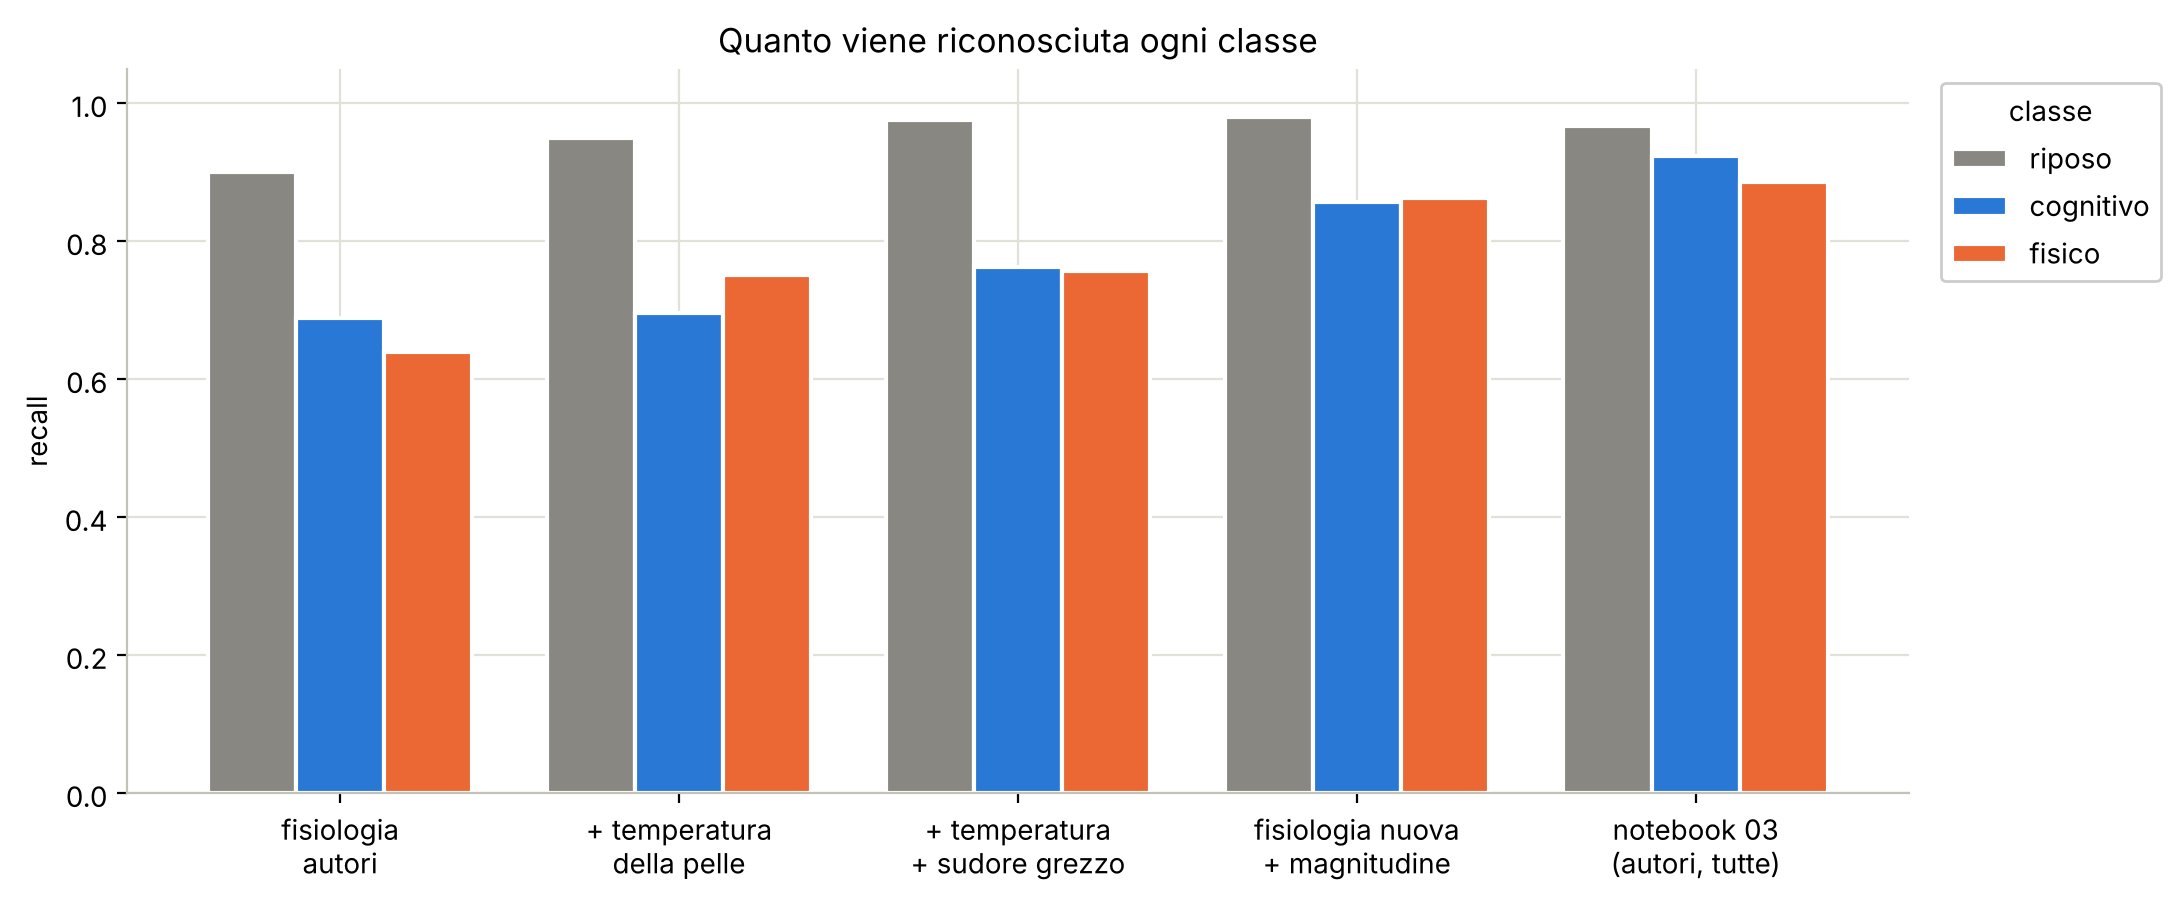

In [20]:
scelte = ["senza movimento | fisiologia autori", "senza movimento | + temperatura della pelle",
          "senza movimento | + temperatura + sudore grezzo",
          "magnitudine | fisiologia nuova", "movimento autori | fisiologia autori (= notebook 03)"]
etichette = ["fisiologia\nautori", "+ temperatura\ndella pelle", "+ temperatura\n+ sudore grezzo",
             "fisiologia nuova\n+ magnitudine", "notebook 03\n(autori, tutte)"]
x = np.arange(len(scelte))

plt.figure(figsize=(11, 4.6))
for k, (classe, colore) in enumerate(zip(nomi_classi, [GRIGIO, BLU, ARANCIO])):
    plt.bar(x + (k - 1) * 0.26, risultati.loc[scelte, classe], width=0.26, color=colore,
            edgecolor="white", linewidth=1.5, label=classe)
plt.xticks(x, etichette)
plt.ylim(0, 1.05)
plt.ylabel("recall")
plt.title("Quanto viene riconosciuta ogni classe")
plt.legend(title="classe", loc="upper left", bbox_to_anchor=(1.01, 1), framealpha=1)
plt.tight_layout()
plt.show()

# Parte 8 — MLP con le feature nuove

## Fase 20 — MLP accanto a Random Forest
La stessa MLP del notebook 03 (due strati da 64 e 32 neuroni, senza early stopping) sulle stesse prove della Fase 16, accanto a Random Forest. Con le feature degli autori le due pareggiano (0,93): la domanda è se, con le feature nuove, la rete ne approfitta di più o di meno. Alcuni minuti di calcolo.

In [21]:
prove_mlp = [nome for nome in prove if not nome.startswith("solo sudore")]
confronto = {}
for nome in prove_mlp:
    rete = prova(tabella, prove[nome], modello="mlp")
    confronto[nome] = {"MLP": rete["accuracy"], "RF": risultati.loc[nome, "accuracy"],
                       "MLP cognitivo": rete["cognitivo"], "MLP fisico": rete["fisico"]}
confronto = pd.DataFrame(confronto).T
confronto.round(2)

,MLP,RF,MLP cognitivo,MLP fisico
senza movimento | fisiologia autori,0.75,0.75,0.67,0.68
senza movimento | + temperatura della pelle,0.75,0.80,0.68,0.68
senza movimento | + temperatura + sudore grezzo,0.80,0.84,0.74,0.72
magnitudine | fisiologia nuova,0.86,0.90,0.82,0.85
movimento autori | fisiologia autori (= notebook 03),0.93,0.93,0.91,0.93
movimento autori | tutte le feature,0.93,0.95,0.92,0.90


## Fase 21 — MLP: il guadagno è stabile?
Le tre prove senza movimento con la MLP, ripetute con 5 semi diversi (da confrontare con la Fase 17).

In [22]:
semi_mlp = pd.DataFrame({nome: [prova(tabella, prove[nome], seme, modello="mlp")["accuracy"] for seme in range(5)]
                         for nome in ["senza movimento | fisiologia autori", "senza movimento | + temperatura della pelle",
                                      "senza movimento | + temperatura + sudore grezzo"]})
semi_mlp.index.name = "seme"
print(semi_mlp.round(3))
print("\nMedia MLP:", semi_mlp.mean().round(3).to_dict())
print("Media RF: ", semi.mean().round(3).to_dict())

      senza movimento | fisiologia autori  \
seme                                        
0                                   0.750   
1                                   0.738   
2                                   0.745   
3                                   0.734   
4                                   0.750   

      senza movimento | + temperatura della pelle  \
seme                                                
0                                           0.766   
1                                           0.759   
2                                           0.762   
3                                           0.753   
4                                           0.763   

      senza movimento | + temperatura + sudore grezzo  
seme                                                   
0                                               0.784  
1                                               0.784  
2                                               0.767  
3                               

## Fase 22 — MLP: stress cognitivo contro stress fisico
Lo stesso controllo della Fase 18, senza riposo, con la MLP. Media su 3 semi.

In [23]:
controllo_mlp = {}
for nome, colonne_usate in {"fisiologia autori": fisiologia_autori,
                            "+ temperatura della pelle": fisiologia_temperatura,
                            "+ temperatura + sudore grezzo": fisiologia_nuova}.items():
    controllo_mlp[nome] = {"MLP": np.mean([prova(solo_stress, colonne_usate, seme, modello="mlp")["accuracy"] for seme in range(3)]),
                           "RF": controllo[nome]}
pd.DataFrame(controllo_mlp).T.round(3)

,MLP,RF
fisiologia autori,0.715,0.718
+ temperatura della pelle,0.720,0.762
+ temperatura + sudore grezzo,0.726,0.780


**Cosa dice.** Con le feature degli autori MLP e Random Forest pareggiano. Con le feature nuove, senza movimento, la MLP migliora meno (circa da 0,74 a 0,78, contro 0,75 → 0,83 di Random Forest), e nel confronto stress cognitivo contro fisico quasi non migliora. Le feature nuove aiutano soprattutto i modelli ad alberi: un modello più complesso non porta vantaggi su questi dati, anzi ne approfitta meno.

## Note
- Stesse righe del notebook 03 (blocchi da 30 s, 4 fasi, stesse correzioni): i risultati si confrontano direttamente
- Magnitudine: misura del movimento che non dipende da come è girato il braccialetto; nelle nostre prove sostituisce il movimento degli autori, che resta solo per il confronto con il paper
- `temp_sk1` coincide con `cbt`, la temperatura interna stimata dal braccialetto: per questo è quasi costante. La temperatura della pelle (`skin_temp`) e il flusso di calore vengono dal file `heat_flux_sensor_temperature` (1 Hz)
- Il riposo è sempre la prima fase: il controllo cognitivo contro fisico (Fase 18) serve a escludere che la pendenza riconosca solo il braccialetto appena indossato
- Sudore: il segnale grezzo `bioz` (conduttanza, 25 Hz) al posto dell'indice `stress_skin`; livello e pendenza dipendono anche dall'ordine delle fasi (elettrodo che si assesta all'inizio, sudore che resta alto dopo la corsa), le reazioni meno. La soglia delle reazioni (1%) è stata provata fra 0,5% e 5% senza differenze
- Battito (PPG): la variabilità del battito non è misurabile in modo affidabile durante i compiti (Parte 5) e resta fuori dal modello
- MLP: la stessa del notebook 03 (64 e 32 neuroni, senza early stopping), nessuna ricerca degli iperparametri (decisione 32)